In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
# Cell 1: Part 0 - Environment Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("Environment successfully set up!")

Environment successfully set up!


In [2]:
# Cell 2: Part 1 - Generate & Load Synthetic GA4 Session Logs
np.random.seed(42)
n_rows = 5000

session_ids = [f"sess_{i:04d}" for i in range(1, n_rows + 1)]
user_ids = [f"user_{np.random.randint(1000, 2000)}" for _ in range(n_rows)]
device_categories = np.random.choice(['desktop', 'mobile', 'tablet'], size=n_rows, p=[0.5, 0.4, 0.1])

session_start_flag = np.ones(n_rows, dtype=int)
add_to_cart_flag = np.random.choice([0, 1], size=n_rows, p=[0.7, 0.3])
purchase_flag = np.where(add_to_cart_flag == 1, np.random.choice([0, 1], size=n_rows, p=[0.4, 0.6]), 0)

page_views = np.random.poisson(lam=3, size=n_rows) + 1
time_on_site_sec = page_views * np.random.randint(20, 60, size=n_rows)

df = pd.DataFrame({
    'session_id': session_ids,
    'user_id': user_ids,
    'device_category': device_categories,
    'session_start_flag': session_start_flag,
    'add_to_cart_flag': add_to_cart_flag,
    'purchase_flag': purchase_flag,
    'page_views': page_views,
    'time_on_site_sec': time_on_site_sec
})

# Introduce 50 artificial missing values[cite: 1]
df.loc[np.random.choice(n_rows, 50), 'time_on_site_sec'] = np.nan

df.to_csv('ga4_sample_session_logs.csv', index=False)
print("Dataset 'ga4_sample_session_logs.csv' successfully generated and loaded!")
display(df.head())
df.info()

Dataset 'ga4_sample_session_logs.csv' successfully generated and loaded!


,session_id,user_id,device_category,session_start_flag,add_to_cart_flag,purchase_flag,page_views,time_on_site_sec
0,sess_0001,user_1102,tablet,1,0,0,5,155.0
1,sess_0002,user_1435,desktop,1,0,0,3,171.0
2,sess_0003,user_1860,tablet,1,0,0,2,110.0
3,sess_0004,user_1270,desktop,1,0,0,4,140.0
4,sess_0005,user_1106,desktop,1,1,0,4,80.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   session_id          5000 non-null   object 
 1   user_id             5000 non-null   object 
 2   device_category     5000 non-null   object 
 3   session_start_flag  5000 non-null   int64  
 4   add_to_cart_flag    5000 non-null   int64  
 5   purchase_flag       5000 non-null   int64  
 6   page_views          5000 non-null   int64  
 7   time_on_site_sec    4950 non-null   float64
dtypes: float64(1), int64(4), object(3)
memory usage: 312.6+ KB


In [3]:
# Cell 3: Part 2 - Digital Conversion Funnel[cite: 1]
total_sessions = df['session_id'].nunique()
sessions_with_cart = df[df['add_to_cart_flag'] == 1]['session_id'].nunique()
sessions_with_purchase = df[df['purchase_flag'] == 1]['session_id'].nunique()

funnel_df = pd.DataFrame({
    'Funnel Step': ['1. Session Start', '2. Add to Cart', '3. Purchase'],
    'User Sessions': [total_sessions, sessions_with_cart, sessions_with_purchase]
})

funnel_df['Conversion Rate (%)'] = (funnel_df['User Sessions'] / total_sessions) * 100
# Optional: Step-to-step conversion rate for deeper analysis
funnel_df['Step-to-Step Conversion (%)'] = (funnel_df['User Sessions'] / funnel_df['User Sessions'].shift(1).fillna(total_sessions)) * 100
display(funnel_df)

,Funnel Step,User Sessions,Conversion Rate (%),Step-to-Step Conversion (%)
0,1. Session Start,5000,100.0,100.000000
1,2. Add to Cart,1470,29.4,29.400000
2,3. Purchase,905,18.1,61.564626


In [4]:
# Cell 4: Part 3 - Data Cleaning & Missing Value Imputation[cite: 1]
print("Missing values before cleaning:\n", df.isnull().sum())

median_time = df['time_on_site_sec'].median()
df['time_on_site_sec'] = df['time_on_site_sec'].fillna(median_time)
df = df.dropna(subset=['session_id'])
df['device_category'] = df['device_category'].str.lower().str.strip()

print("\nData cleaning completed. Missing values remaining:", df.isnull().sum().sum())

Missing values before cleaning:
 session_id             0
user_id                0
device_category        0
session_start_flag     0
add_to_cart_flag       0
purchase_flag          0
page_views             0
time_on_site_sec      50
dtype: int64

Data cleaning completed. Missing values remaining: 0


                    session_start_flag  add_to_cart_flag  purchase_flag  \
session_start_flag                 NaN               NaN            NaN   
add_to_cart_flag                   NaN          1.000000       0.728494   
purchase_flag                      NaN          0.728494       1.000000   
page_views                         NaN         -0.010963      -0.000583   
time_on_site_sec                   NaN          0.001849       0.004230   

                    page_views  time_on_site_sec  
session_start_flag         NaN               NaN  
add_to_cart_flag     -0.010963          0.001849  
purchase_flag        -0.000583          0.004230  
page_views            1.000000          0.804072  
time_on_site_sec      0.804072          1.000000  


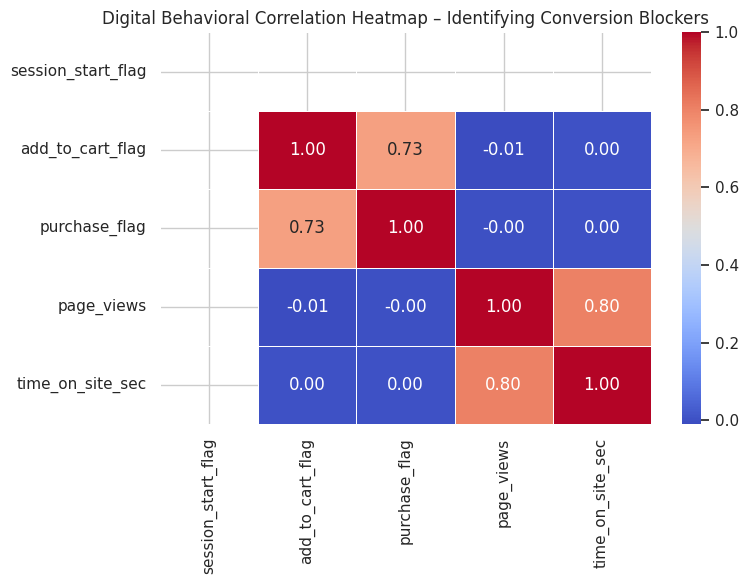

In [5]:
# Cell 5: Part 4 - Correlation Matrix & Seaborn Heatmap[cite: 1]
numeric_cols = ['session_start_flag', 'add_to_cart_flag', 'purchase_flag', 'page_views', 'time_on_site_sec']
corr_matrix = df[numeric_cols].corr()
print(corr_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Digital Behavioral Correlation Heatmap – Identifying Conversion Blockers", fontsize=12)
plt.tight_layout()
plt.show()